# model verisi ve baseline

bu notebookta caltech oturumlarından model tablosunu çıkarıyorum, eğitim doğrulama test sınırlarını ayırıyorum ve doğrulama kümesinde ilk karşılaştırmayı yapıyorum. test kısmına hiç bakmıyorum.

src klasörünü import edebilmek için proje klasörünü yola ekliyorum. sonra 14 çeyrek dosyasını okuyup saatlik doluluk matrisini çıkarıyorum.

In [1]:
import sys
from pathlib import Path

import pandas as pd

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from src.load_data import load_caltech_sessions, build_occupancy_matrix
from src.features.lags import build_model_table
from src.split import assign_split

sessions = load_caltech_sessions()
occupancy = build_occupancy_matrix(sessions)
print("oturum:", sessions.shape)
print("saatlik matris:", occupancy.shape)

oturum: (31424, 17)
saatlik matris: (29705, 55)


her satır bir nokta ve bir saat olacak şekilde uzun tabloya çeviriyorum. özellikler önceki saat, önceki gün, önceki hafta, geçmiş saatlerin ortalaması ve takvim bilgileri. sonra her saate train val test ya da masked etiketi veriyorum.

In [2]:
table = build_model_table(occupancy)
assert len(table) == (29705 - 168) * 55

table["split"] = table["hour_utc"].map(assign_split(occupancy.index))

summary = table.groupby("split")["occupied"].agg(satir="count", dolu="sum", oran="mean")
summary["saat"] = table.groupby("split")["hour_utc"].nunique()
print("model tablosu:", table.shape)
summary

model tablosu: (1624535, 16)


,satir,dolu,oran,saat
split,,,,
masked,323400,2936,0.009079,5880
test,418660,9984,0.023848,7612
train,681835,140173,0.205582,12397
val,200640,22788,0.113577,3648


bölmeyi günlük dolu nokta saat sayısı üzerinden çiziyorum. masked dönem 2020 mart ile ekim arası.

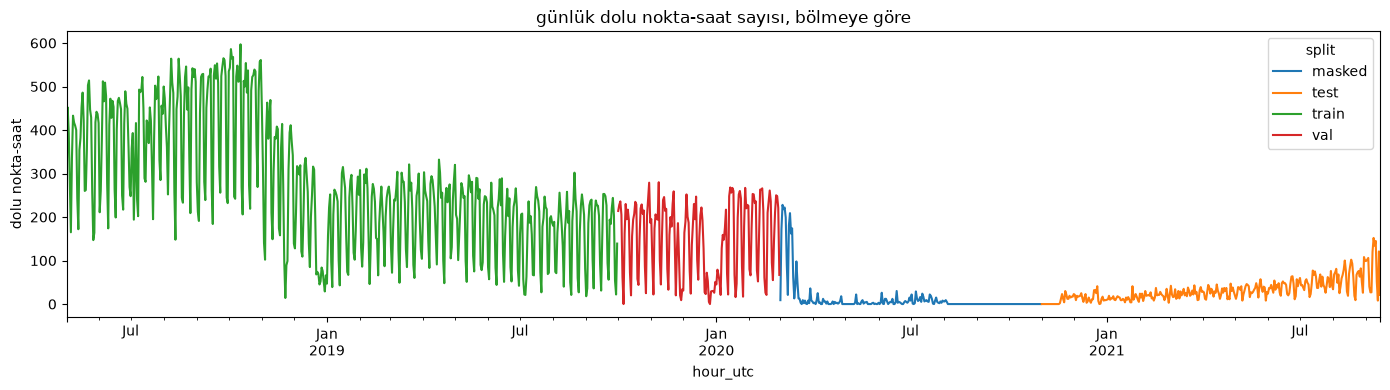

In [3]:
import matplotlib.pyplot as plt

figure_dir = project_dir / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

daily = (
    table.groupby([table["hour_utc"].dt.floor("D"), "split"])["occupied"]
    .sum()
    .unstack("split")
)
daily.plot(figsize=(14, 4), title="günlük dolu nokta-saat sayısı, bölmeye göre")
plt.ylabel("dolu nokta-saat")
plt.tight_layout()
plt.savefig(figure_dir / "split_dagilimi.png", dpi=150)
plt.show()

doğrulama kümesinde dört yöntemi karşılaştırıyorum. önceki saat ve önceki hafta modelsiz tahminler. logistic regression ve random forest eğitim kümesinden öğreniyor. ölçekleme de sadece eğitimden öğreniliyor. random forest için karar eşiğini doğrulama kümesinde f1e göre seçiyorum.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_curve, precision_score, recall_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

features = [
    "prev_hour", "prev_day", "prev_week", "mean_6h", "mean_24h",
    "hour_local", "day_of_week_local", "is_weekend_local",
    "is_holiday", "is_academic_break", "month_local", "station_code",
]
train = table[table["split"] == "train"]
val = table[table["split"] == "val"]
y_train, y_val = train["occupied"], val["occupied"]


def scores(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


results = [
    scores("önceki saat", y_val, val["prev_hour"]),
    scores("önceki hafta", y_val, val["prev_week"]),
]

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(train[features], y_train)
results.append(scores("logistic regression", y_val, logreg.predict(val[features])))

forest = RandomForestClassifier(
    n_estimators=100, max_depth=12, min_samples_leaf=20,
    max_samples=0.3, n_jobs=-1, random_state=42,
)
forest.fit(train[features], y_train)
proba = forest.predict_proba(val[features])[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, proba)
f1_values = 2 * precision * recall / (precision + recall + 1e-12)
best_threshold = thresholds[f1_values[:-1].argmax()]
results.append(scores("random forest", y_val, proba >= best_threshold))

print("random forest eşiği:", round(float(best_threshold), 3))
pd.DataFrame(results).round(3)

random forest eşiği: 0.426


,model,accuracy,precision,recall,f1
0,önceki saat,0.964,0.843,0.844,0.843
1,önceki hafta,0.884,0.488,0.485,0.486
2,logistic regression,0.964,0.843,0.843,0.843
3,random forest,0.964,0.835,0.856,0.845
